In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/19/2022
# version ='1.0'

# Demo: Further Experiments on Barrier Method Convergence in Solving the Geometric Programming

In book-convex-2004 an algorithm to solve the Geometric Programming using the barrier method was discussed. The geometric program in convex form is
\begin{equation}
\begin{array}{rcl}
\text{minimize} & f_0(x)=\displaystyle{\log\left(\sum_{k=1}^{K_0}\exp(a_{0,k}^Tx+b_{0,k})\right)} \\
\text{subject to} & f_i(x)=\displaystyle{\log\left(\sum_{k=1}^{K_i}\exp(a_{i,k}^Tx+b_{i,k}) \right)} \leq 0 & i=1,...,m \\
\end{array}
\end{equation}
where $x\in \mathbf{R}^n$. 

In the discussion, the variation of the total number of Newton steps required to solve the problem, versus the parameter $\mu$, was discussed, and from the figure 11.6 in the textbook, it appeared that the larger $\mu$ was, the faster convergence it could achieve. 

However, the variation of the convergence speed versus the number of active constraints (denoted as $L$) at the optimal point is not discussed. In this demo, further experiments have been designed to visualize the relations between the convergence speed versus different $L$.

Here are the experiment results, with different number of active constraints (i.e., $L$) for a geometric programming problem with $n=50, m=100, K_i=n=50,i=0,...,m$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

$f_0(x)=\log(r_0)$

$\nabla f_0(x)=\dfrac{\nabla r_0}{r_0}$

$\nabla^2 f_0(x) = \dfrac{-1}{r_0^2}(\nabla r_0)(\nabla r_0)^T + \dfrac{1}{r_0}\nabla^2 r_0$

In [3]:
def my_f_0(r, g_r, h_r):
    """
    $f_0(x)=\log(r_0)$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return np.log(r[0])


def my_f_0_feasible(r, g_r, h_r):
    return True


def my_gradient_f_0(r, g_r, h_r):
    """
    $\nabla f_0(x)=\dfrac{\nabla r_0}{r_0}$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return g_r[0] / r[0]


def my_hessian_f_0(r, g_r, h_r):
    """
    $\nabla^2 f_0(x) = \dfrac{-1}{r_0^2}(\nabla r_0)(\nabla r_0)^T + \dfrac{1}{r_0}\nabla^2 r_0$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    hessian = (-1) / (r[0] ** 2) * (g_r[0] @ g_r[0].T) + 1 / r[0] * h_r[0]

    if not np.all(np.linalg.eigvals(hessian) > 0):
        if not np.allclose(np.min(np.linalg.eigvals(hessian)), 0):
            raise RuntimeError('the hessian of f0 should be semi positive.')
    return hessian

$\phi(x) = -\displaystyle{\sum_{i=1}^m \log(-\log(r_i))}$

It requires $\log(r_i)<0$

$\nabla \phi(x) = -\displaystyle{\sum_{i=1}^m \dfrac{1}{\log(r_i)}\dfrac{1}{r_i}\nabla r_i}$

$\nabla^2 \phi(x) = -\displaystyle{\sum_{i=1}^m}\{-\dfrac{1+\log(r_i)}{r_i^2(\log(r_i))^2}(\nabla r_i)(\nabla r_i)^T + \dfrac{1}{\log(r_i)}\dfrac{1}{r_i}\nabla^2 r_i\}$

In [4]:
def my_phi(r, g_r, h_r):
    """
    $\phi(x) = -\displaystyle{\sum_{i=1}^m \log(-\log(r_i))}$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    m = len(r) - 1
    s = 0
    for i in range(1, m + 1):
        s -= np.log(-np.log(r[i]))
    return s


def my_phi_feasible(r, g_r, h_r):
    """
    It requires $\log(r_i)<0$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return np.all(np.log(r[1:]) < 0)


def my_gradient_phi(r, g_r, h_r):
    """
    $\nabla \phi(x) = -\displaystyle{\sum_{i=1}^m \dfrac{1}{\log(r_i)}\dfrac{1}{r_i}\nabla r_i}$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    m = len(r) - 1
    gradient = -1 * (1 / (np.log(r[1]))) * (1 / r[1]) * g_r[1]
    for i in range(2, m + 1):
        gradient += -1 * (1 / (-np.log(r[i]))) * (-1 / r[i] * g_r[i])
    return gradient


def my_hessian_phi(r, g_r, h_r):
    """
    $\nabla^2 \phi(x) = -\displaystyle{\sum_{i=1}^m}\{-\dfrac{1+\log(r_i)}{r_i^2(\log(r_i))^2}(\nabla r_i)(\nabla r_i)^T + \dfrac{1}{\log(r_i)}\dfrac{1}{r_i}\nabla^2 r_i\}$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    m = len(r) - 1
    hessian = -1 * (-1 * (1 + np.log(r[1])) / ((r[1] ** 2) * (np.log(r[1])) ** 2) * (g_r[1] @ g_r[1].T) + 1 / np.log(
        r[1]) * 1 / r[1] * h_r[1])
    for i in range(2, m + 1):
        hessian += -1 * (
                -1 * (1 + np.log(r[i])) / ((r[i] ** 2) * (np.log(r[i])) ** 2) * (g_r[i] @ g_r[i].T) + 1 / np.log(
            r[i]) * 1 / r[i] * h_r[i])
    return hessian

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [5]:
def my_f(t, r, g_r, h_r):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param t:
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return t * my_f_0(r, g_r, h_r) + my_phi(r, g_r, h_r)


def my_f_feasible(t, r, g_r, h_r):
    """
    :param t:
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return my_f_0_feasible(r, g_r, h_r) and my_phi_feasible(r, g_r, h_r)


def my_gradient_f(t, r, g_r, h_r):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param t:
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return t * my_gradient_f_0(r, g_r, h_r) + my_gradient_phi(r, g_r, h_r)


def my_hessian_f(t, r, g_r, h_r):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param t:
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return t * my_hessian_f_0(r, g_r, h_r) + my_hessian_phi(r, g_r, h_r)

Refer to the lecture note for the meaning of ($r, g_r, h_r$)
    For each $x$, ($r, g_r, h_r$) are calculated and cached to avoid
    duplications in later calculations of gradients and hessians.

In [6]:
def my_get_r_gr_hr(x, a, b, K):
    """
    Refer to the lecture note for the meaning of ($r, g_r, h_r$)
    For each $x$, ($r, g_r, h_r$) are calculated and cached to avoid
    duplications in later calculations of gradients and hessians.
    :param x:
    :param a:
    :param b:
    :param K:
    :return:
    """
    K_max = np.max(K)
    m = len(a) - 1
    r = np.zeros((m + 1,))
    g_r = np.zeros((m + 1, n, 1))
    h_r = np.zeros((m + 1, n, n))
    beta = np.zeros((m + 1, K_max))
    for i in range(m + 1):
        for k in range(K[i]):
            beta[i][k] = np.exp(a[i][k].T @ x + b[i][k])

        r[i] = beta[i][0]
        for k in range(1, K[i]):
            r[i] += beta[i][k]

        g_r[i] = beta[i][0] * a[i][0]
        for k in range(1, K[i]):
            g_r[i] += beta[i][k] * a[i][k]

        h_r[i] = beta[i][0] * (a[i][0] @ a[i][0].T)
        for k in range(1, K[i]):
            h_r[i] += beta[i][k] * (a[i][k] @ a[i][k].T)

    return r, g_r, h_r

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [7]:
def my_newton_step_decrement(args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param args:
    :return:
    """
    gradient = my_gradient_f(*args)
    hessian = my_hessian_f(*args)
    hessian_inv = np.linalg.inv(hessian)
    x_nt = -1 * hessian_inv @ gradient
    decrement = -1 * gradient.T @ x_nt
    return x_nt, decrement.item()

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [8]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, a, b, K, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param a:
    :param b:
    :param K:
    :param args:
    :return:
    """
    s = 1
    t = args[0]

    next_x = x + s * delta_x
    next_r, next_gr, next_hr = my_get_r_gr_hr(next_x, a, b, K)
    next_args = (t, next_r, next_gr, next_hr)

    while (not my_f_feasible(*next_args)) \
            or f(*next_args) > f(*args) + alpha * s * ((df(*args).T @ delta_x).item()):
        s = beta * s
        next_x = x + s * delta_x
        next_r, next_gr, next_hr = my_get_r_gr_hr(next_x, a, b, K)
        next_args = (t, next_r, next_gr, next_hr)
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [9]:
def centering_step(x0, epsilon, t, a, b, K, alpha, beta):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param t:
    :param a:
    :param b:
    :param K:
    :param alpha:
    :param beta:
    :return:
    """
    x = x0
    r0, g_r0, h_r0 = my_get_r_gr_hr(x0, a, b, K)
    args = (t, r0, g_r0, h_r0)

    x_nt, decrement = my_newton_step_decrement(args)

    fx = []
    sx = []
    decrements = []
    fx.append(my_f(*args))
    decrements.append(decrement)

    iteration = 1  # a Newton iteration has been executed
    while decrement / 2 > epsilon:

        s = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, a, b, K, args)
        #print(r'Info: iteration={}, decrement={}, s={}'.format(iteration, decrement, s))
        sx.append(s)

        x_next = x + s * x_nt
        x = x_next
        next_r, next_gr, next_hr = my_get_r_gr_hr(x_next, a, b, K)
        args = (t, next_r, next_gr, next_hr)
        x_nt, decrement = my_newton_step_decrement(args)

        fx.append(my_f(*args))
        decrements.append(decrement)

        iteration = iteration + 1

    #print(r'Info: iteration={}, decrement={}'.format(iteration, decrement))
    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, sx

 Given n, m, K, l, generate model parameter, a, b, with optimal value f_asterisk
 
Refer to Algorithm-1 in the lecture note

In [10]:
def get_model_parameters(n, m, K, L, f_asterisk):
    """
    Given n, m, K, L
    Generate model parameter, a, b, with optimal value f_asterisk
    Refer to Algorithm-1 in the lecture note
    :param n:
    :param m:
    :param K:
    :param L:
    :param f_asterisk:
    :return:
    """
    num_zero_lambda = m-L
    lambda_ = np.random.rand(m + 1)
    if num_zero_lambda > 0:
        lambda_[1: num_zero_lambda + 1] = 0

    K_max = np.max(K)
    r = np.zeros((m + 1,))
    g_r = np.zeros((m + 1, n, 1))
    h_r = np.zeros((m + 1, n, n))
    beta = np.zeros((m + 1, K_max, 1))

    a = [[]] * (m + 1)
    b = [[]] * (m + 1)

    x_asterisk = np.random.rand(n, 1)
    for i in range(1, m + 1):
        if lambda_[i] != 0:
            r[i] = 1
        else:
            r[i] = np.random.sample()

        eta_i_tmp = np.random.rand(K[i], 1)
        sum_tmp = np.sum(eta_i_tmp)
        beta[i] = r[i] * eta_i_tmp / sum_tmp
        if not np.allclose(np.sum(beta[i]), r[i]):
            raise RuntimeError('sum of beta_i,k should be r[i]')

        a[i] = [[]] * K[i]
        b[i] = [[]] * K[i]

        for k in range(K[i]):
            a[i][k] = np.random.rand(n, 1)
            b[i][k] = np.log(beta[i][k]) - (a[i][k].T @ x_asterisk).item()
            g_r[i] += beta[i][k] * a[i][k]

        if not np.allclose(np.sum([np.exp(a[i][k].T @ x_asterisk + b[i][k]) for k in range(K[i])]), r[i]):
            raise RuntimeError('sum of exp(a[i][k]x_p + b[i][k]) should be r[i].')

    theta = np.zeros((n, 1))
    for i in range(1, m + 1):
        theta = theta - lambda_[i] / r[i] * g_r[i]

    r[0] = np.exp(f_asterisk)
    eta_tmp = np.random.rand(K[0], 1)
    sum_tmp = np.sum(eta_tmp)
    eta = eta_tmp / sum_tmp
    beta[0] = r[0] * eta

    a[0] = [[]] * K[0]
    b[0] = [[]] * K[0]
    a[0][0] = theta / eta[0]
    for k in range(1, K[0]):
        a[0][k] = np.random.rand(n, 1)
        b[0][k] = np.log(beta[0][k]) - (a[0][k].T @ x_asterisk).item()
        a[0][0] -= (eta[k] * a[0][k]) / eta[0]

    b[0][0] = np.log(beta[0][0]) - (a[0][0].T @ x_asterisk).item()

    g_r[0] = np.zeros((n, 1))
    for k in range(K[0]):
        g_r[0] += beta[0][k] * a[0][k]

    for i in range(m + 1):
        h_r[i] = np.zeros((n, n))
        for k in range(K[i]):
            h_r[i] += beta[i][k] * (a[i][k] @ a[i][k].T)

    if not np.allclose(np.log(np.sum([np.exp(a[0][k].T @ x_asterisk + b[0][k]) for k in range(K[0])])), f_asterisk):
        raise RuntimeError('The optimal value should be p^asterisk={}'.format(f_asterisk))

    for i in range(m + 1):
        sum_tmp = np.zeros((n, 1))
        for k in range(K[i]):
            sum_tmp += beta[i][k] * a[i][k]
        if not np.allclose(sum_tmp, g_r[i]):
            raise RuntimeError(r'Something wrong in calculation of $\nabla$ gamma')

        if i != 0:
            if not np.allclose(lambda_[i] * np.log(r[i]), 0):
                raise RuntimeError(r'the optimal condition $\lamba_i\log(r_i)$=0 is not satisfied.')

    grad = 1 / r[0] * g_r[0]
    for i in range(1, m + 1):
        grad += lambda_[i] / r[i] * g_r[i]

    if not np.allclose(grad, np.zeros((n, 1))):
        raise RuntimeError(r'the $\dfrac{\nabla r_0}{r_0} + \displaystyle{\sum_{i=1}^m\lambda_i \dfrac{\nabla r_i}{r_i}} = 0$ optimal condition 1 is not satisfied.')

    return a, b, beta, r, g_r, h_r, x_asterisk

In [11]:
def get_feasible_start_at_zeros(xp):
    """
    x=0 is always a string feasible point
    :param xp:
    :return:
    """
    return np.zeros(xp.shape)

Given x_asterisk, f_asterisk, to find a start point with a duality gap equal to delta

Refer to Algorithm-1 in the lecture note

In [12]:
def get_feasible_start_with_duality_gap(a, b, K, x_asterisk, f_asterisk, delta):
    """
    Given x_asterisk, f_asterisk, to find a start point with a duality gap equal to delta
    Refer to Algorithm-1 in the lecture note
    :param a:
    :param b:
    :param K:
    :param x_asterisk:
    :param f_asterisk:
    :param delta:
    :return:
    """
    zeros = get_feasible_start_at_zeros(x_asterisk)
    r_zeros, gr_zeros, hr_zeros = my_get_r_gr_hr(zeros, a, b, K)
    f = my_f_0(r_zeros, gr_zeros, hr_zeros)
    x_low = x_asterisk
    x_high = zeros
    x = -x_asterisk
    while f < (f_asterisk + delta):
        x_low = x_high
        x = 2 * x
        x_high = x
        r, gr, hr = my_get_r_gr_hr(x, a, b, K)
        f = my_f_0(r, gr, hr)

    x_mid = (x_low + x_high) / 2
    r, gr, hr = my_get_r_gr_hr(x_mid, a, b, K)
    f_mid = my_f_0(r, gr, hr)
    while not np.allclose(f_mid, (f_asterisk + delta)):
        if f_mid > f_asterisk + delta:
            x_high = x_mid
        else:
            x_low = x_mid

        x_mid = (x_low + x_high) / 2
        r, gr, hr = my_get_r_gr_hr(x_mid, a, b, K)
        f_mid = my_f_0(r, gr, hr)

    return x_mid

In [13]:
def plot_barrier_method_convergence_vs_num_active_constraints(m, n, L, seed):
    """
    Plot the convergence figure versus different value of L (i.e., the number of active constraints at the optimal point)
    :param m:
    :param n:
    :param L:
    :param seed:
    :return:
    """
    np.random.seed(seed)

    plt.figure(figsize=(12, 6))

    K = [n] * (m + 1)
    f_asterisk = 0

    a, b, beta, r, g_r, h_r, x_asterisk = get_model_parameters(n, m, K, L, f_asterisk)

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1e-3

    ax1 = plt.subplot(2, 1, 1)
    ax1_twin = ax1.twinx()

    ax2 = plt.subplot(2, 1, 2)
    ax2_twin = ax2.twinx()

    t0 = 1

    duality_gap_delta = 100
    x0 = get_feasible_start_with_duality_gap(a, b, K, x_asterisk, f_asterisk, duality_gap_delta)
    r_x0, gr_x0, hr_x0 = my_get_r_gr_hr(x0, a, b, K)
    f_x0 = my_f_0(r_x0, gr_x0, hr_x0)

    mus = [2, 50, 150]
    colors = ['orange', 'purple', 'green']
    max_iteration = 0
    for mu_i, mu in enumerate(mus):
        t = t0
        x = x0.copy()

        iteration_counter = 0
        f0_x_all = []
        decrement_all = []
        step_t_all = []
        iteration_index_vs_fx = []
        iteration_index_vs_decrement = []
        iteration_index_vs_step_t = []
        while True:
            xt, n_iter, fx, decrement, ts = centering_step(x, epsilon, t, a, b, K, alpha, beta)

            # save the intermediate statistics
            args = my_get_r_gr_hr(x, a, b, K)
            f0_x_all = f0_x_all + [my_f_0(*args)] * n_iter
            decrement_all.append(decrement)
            step_t_all.append(ts)
            iteration_index_vs_decrement = iteration_index_vs_decrement + [x for x in
                                                                           range(iteration_counter, iteration_counter + n_iter)]
            iteration_index_vs_fx = iteration_index_vs_fx + [x for x in range(iteration_counter, iteration_counter + n_iter)]
            iteration_index_vs_step_t = iteration_index_vs_step_t + [x for x in
                                                                     range(iteration_counter + 1, iteration_counter + n_iter)]
            iteration_counter = iteration_counter + n_iter - 1
            x = xt

            if m / t < duality_gap_epsilon:
                args = my_get_r_gr_hr(xt, a, b, K)
                iteration_index_vs_fx.append(max(iteration_index_vs_fx))
                f0_x_all.append(my_f_0(*args))
                break
            else:
                t = mu * t

        r, gr, hr = my_get_r_gr_hr(x, a, b, K)

        #print('Info: |x0-x_asterisk|={}'.format(np.linalg.norm(x0 - x_asterisk)))
        #print('Info: |xt-x_asterisk|={}'.format(np.linalg.norm(xt - x_asterisk)))

        #print('Info: f0={}'.format(f_x0))
        #print('Info: f_asterisk={}'.format(f_asterisk))
        #print('Info: ft={}'.format(my_f_0(r, gr, hr)))

        zera = 1e-14

        all_decrement = np.array([x for y in decrement_all for x in y])
        ax1.semilogy(iteration_index_vs_fx, np.abs(np.array(f0_x_all) - f_asterisk) + zera, color=colors[mu_i],
                     linestyle='solid', fillstyle='none', marker='+',
                     label=r'$f_0(x)-f_0^*(\mu={})$'.format(mu))

        ax1_twin.semilogy(iteration_index_vs_decrement, all_decrement, color=colors[mu_i], linestyle='dashed',
                          fillstyle='none', marker='x',
                          label=r'$\lambda^2(\mu={})$'.format(mu))

        all_ts = np.array([x for y in step_t_all for x in y])
        ax2.semilogy(iteration_index_vs_fx, np.abs(np.array(f0_x_all) - f_asterisk) + zera, color=colors[mu_i],
                     linestyle='solid', fillstyle='none', marker='+',
                     label=r'$f_0(x)-f_0^*(\mu={})$'.format(mu))

        ax2_twin.plot(iteration_index_vs_step_t, all_ts, color=colors[mu_i], linestyle='dashed', fillstyle='none',
                      marker='x',
                      label=r'backtracking line search step: t$(\mu={})$'.format(mu))

        max_iteration = max(max_iteration, max(iteration_index_vs_fx))

    ax1.legend(loc=4)
    ax1.set_xlim(0, max_iteration + 5)
    ax1_twin.set_xlim(0, max_iteration + 5)
    ax1_twin.legend(loc=1)
    ax1.grid()
    ax1.set_xlabel('iteration')
    ax1.set_ylabel(r'$f_0(x)-f_0^*$')
    ax1_twin.set_ylabel(r'$\lambda^2$')
    ax1.set_title('geometric programing, n={},m={},K={},L={}'.format(n, m, K[0], L))

    ax2.legend(loc=4)
    ax2.set_xlim(0, max_iteration + 5)
    ax1_twin.set_xlim(0, max_iteration + 5)
    ax2_twin.legend(loc=1)
    ax2.grid()
    ax2.set_xlabel('iteration')
    ax2.set_ylabel(r'$f_0(x)-f_0^*$')
    ax2_twin.set_ylabel(r'step t')
    ax2_twin.set_ylim(0, 1.5)

    plt.show()

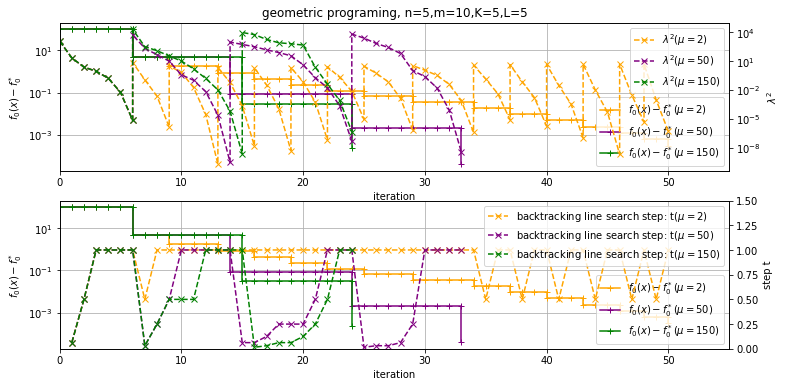

In [14]:
if __name__ == "__main__":
    seed = 2
    m = 10
    n = 5
    L = 5
    plot_barrier_method_convergence_vs_num_active_constraints(m, n, L, seed)